In [19]:
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

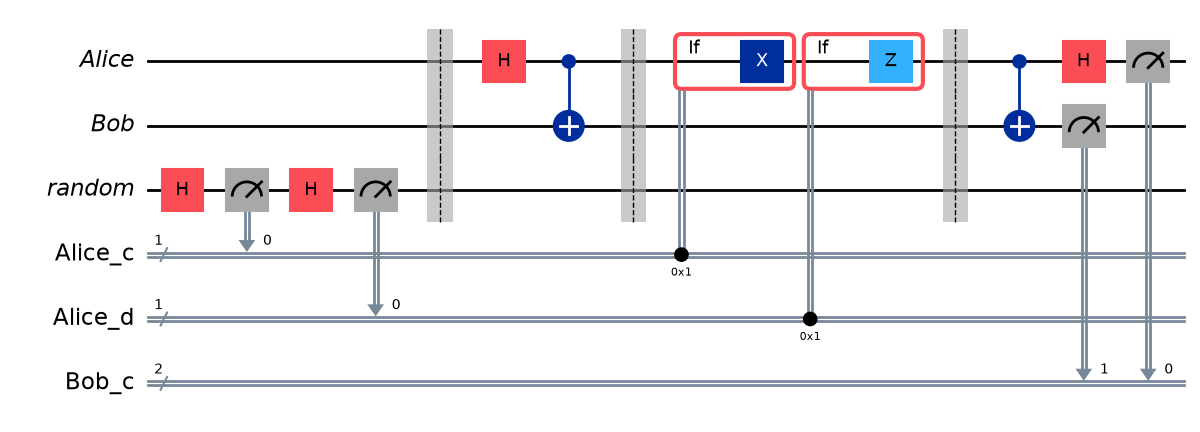

In [15]:
# Use additional qubit to generate random bits that you are sending
random_qubit = QuantumRegister(1, 'random')
Alice = QuantumRegister(1, 'Alice')
Bob = QuantumRegister(1, 'Bob')

Alice_c = ClassicalRegister(1, 'Alice_c')
Alice_d = ClassicalRegister(1, 'Alice_d')

superdense = QuantumCircuit(Alice, Bob, random_qubit, Alice_c, Alice_d)

# Initialize bits to be sent
superdense.h(random_qubit)
superdense.measure(random_qubit, Alice_c)
superdense.h(random_qubit)
superdense.measure(random_qubit, Alice_d)
superdense.barrier()

# Create entangled pair
superdense.h(Alice)
superdense.cx(Alice, Bob)
superdense.barrier()

# Alice encodes her bits
with superdense.if_test((Alice_c, 1)):
    superdense.x(Alice)
with superdense.if_test((Alice_d, 1)):
    superdense.z(Alice)
superdense.barrier()

# Bob decodes the bits
superdense.cx(Alice, Bob)
superdense.h(Alice)

# Measure the qubits
superdense.add_register(ClassicalRegister(2, 'Bob_c'))
superdense.measure(Alice, superdense.clbits[2])
superdense.measure(Bob, superdense.clbits[3])

display(superdense.draw(output='mpl', filename='superdense_coding.png'))

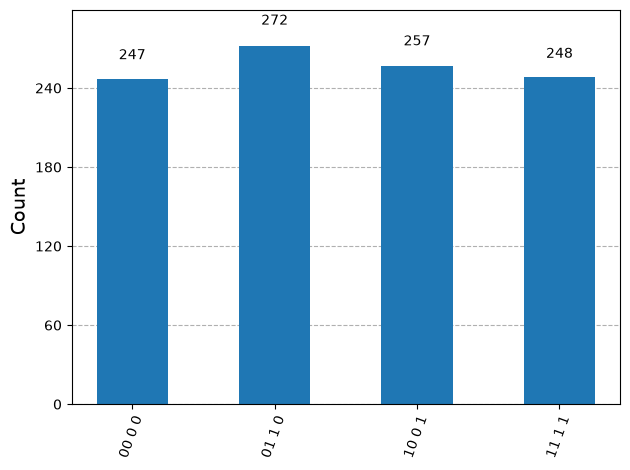

In [20]:
result = AerSimulator().run(superdense).result()
counts = result.get_counts(superdense)
display(plot_histogram(counts))